In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

SEED = 12
CACHE = Path("../cache")
RESULTS = Path("../results"); RESULTS.mkdir(exist_ok=True)
MODELS = Path("../../models"); MODELS.mkdir(exist_ok=True)     

imgs = np.load(CACHE / "images_uint8.npz")
feats = np.load(CACHE / "features.npz")
CLASSES = [str(c) for c in imgs["classes"]]
LABELS = list(range(len(CLASSES)))
y_train, y_test = feats["y_train"], feats["y_test"]
X_test_img = imgs["X_test"]

def to_raw(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

def get_features(name):
    if name == "hist":
        return feats["H_train"], feats["H_test"]
    if name == "pca":
        return feats["P_train"], feats["P_test"]
    if name == "raw":
        return to_raw(imgs["X_train"]), to_raw(X_test_img)
    raise ValueError(name)

print(len(y_train), "train |", len(y_test), "test")

1362 train | 294 test


## Settings chosen on the validation set
Taken from `best_per_model_part_b.csv` (notebook 03) and `kmeans_part_b.csv` (notebook 04).
Edit this cell only if the validation results changed, never because of the test results.

In [2]:

CONFIG = {
    "logreg": {"features": "hist", "C": 10},
    "knn":    {"features": "hist", "k": 1, "weights": "uniform"},
    "kmeans": {"features": "hist", "n_clusters": 5},
}
CONFIG

{'logreg': {'features': 'hist', 'C': 10},
 'knn': {'features': 'hist', 'k': 1, 'weights': 'uniform'},
 'kmeans': {'features': 'hist', 'n_clusters': 5}}

## Helpers
Per-class precision / recall / F1, confusion matrix (fixed class order), most confused pairs, and examples of mistakes.

In [3]:
def per_class_table(y_true, y_pred):
    rep = classification_report(y_true, y_pred, labels=LABELS, target_names=CLASSES,
                                output_dict=True, zero_division=0)
    return pd.DataFrame(rep).T.loc[CLASSES + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3)

def plot_cm(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); plt.tight_layout()
    fig.savefig(RESULTS / fname, dpi=150); plt.show()
    return cm

def top_confusions(cm, n=5):
    pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j]))
             for i in LABELS for j in LABELS if i != j and cm[i, j] > 0]
    return sorted(pairs, key=lambda t: -t[2])[:n]

def show_errors(y_pred, title, fname, n=8):
    wrong = np.where(y_pred != y_test)[0][:n]
    if len(wrong) == 0:
        print("no mistakes to show"); return
    cols = 4; rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).ravel(), wrong):
        ax.imshow(X_test_img[i])
        ax.set_title(f"true {CLASSES[y_test[i]]} / pred {CLASSES[int(y_pred[i])]}", fontsize=9)
    fig.suptitle(title); plt.tight_layout()
    fig.savefig(RESULTS / fname, dpi=150); plt.show()

summary = []

## 1. Logistic Regression

Logistic Regression test accuracy: 0.3061
           precision  recall  f1-score  support
5              0.360   0.525     0.428     59.0
10             0.218   0.200     0.209     60.0
20             0.159   0.167     0.163     60.0
50             0.231   0.150     0.182     60.0
100            0.549   0.509     0.528     55.0
macro avg      0.303   0.310     0.302    294.0


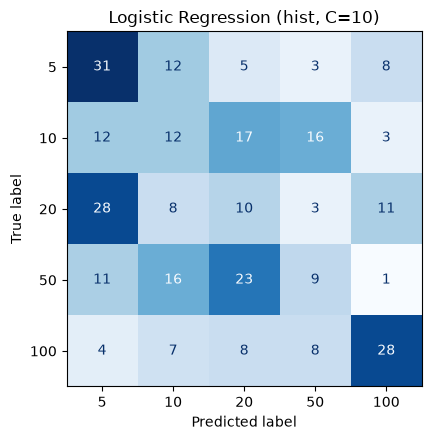

most confused (true, predicted, count): [('20', '5', 28), ('50', '20', 23), ('10', '20', 17), ('10', '50', 16), ('50', '10', 16)]


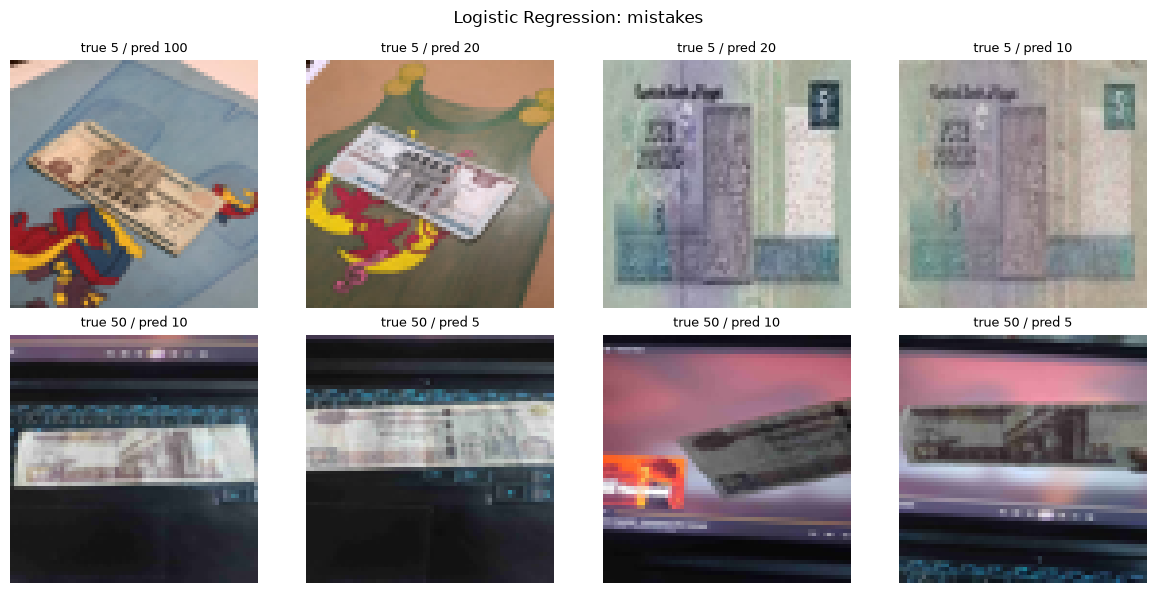

['../../models/part_b_logreg.joblib']

In [4]:
cfg = CONFIG["logreg"]
Xtr, Xte = get_features(cfg["features"])
logreg = make_pipeline(StandardScaler(), LogisticRegression(C=cfg["C"], max_iter=2000, random_state=SEED))
logreg.fit(Xtr, y_train)                       # scaler and model are fit on TRAIN only
pred_lr = logreg.predict(Xte)

acc = accuracy_score(y_test, pred_lr)
print("Logistic Regression test accuracy:", round(acc, 4))
tbl = per_class_table(y_test, pred_lr); print(tbl)
cm = plot_cm(y_test, pred_lr, f"Logistic Regression ({cfg['features']}, C={cfg['C']})", "cm_logreg.png")
print("most confused (true, predicted, count):", top_confusions(cm))
tbl.to_csv(RESULTS / "per_class_logreg.csv")
show_errors(pred_lr, "Logistic Regression: mistakes", "errors_logreg.png")

summary.append({"model": "Logistic Regression", "features": cfg["features"], "setting": f"C={cfg['C']}",
                "accuracy": acc, "macro_f1": f1_score(y_test, pred_lr, average="macro")})
joblib.dump({"model": logreg, "features": cfg["features"], "classes": CLASSES}, MODELS / "part_b_logreg.joblib")

## 2. KNN

KNN test accuracy: 0.2687
           precision  recall  f1-score  support
5              0.368   0.424     0.394     59.0
10             0.333   0.350     0.341     60.0
20             0.103   0.100     0.102     60.0
50             0.158   0.100     0.122     60.0
100            0.313   0.382     0.344     55.0
macro avg      0.255   0.271     0.261    294.0


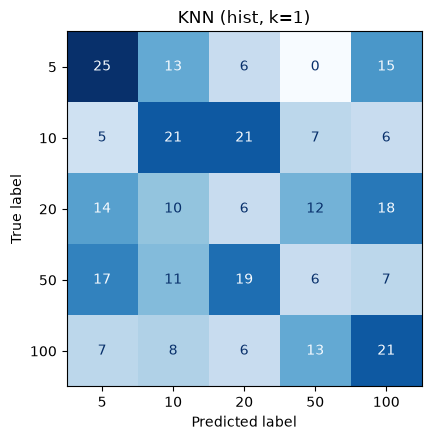

most confused (true, predicted, count): [('10', '20', 21), ('50', '20', 19), ('20', '100', 18), ('50', '5', 17), ('5', '100', 15)]


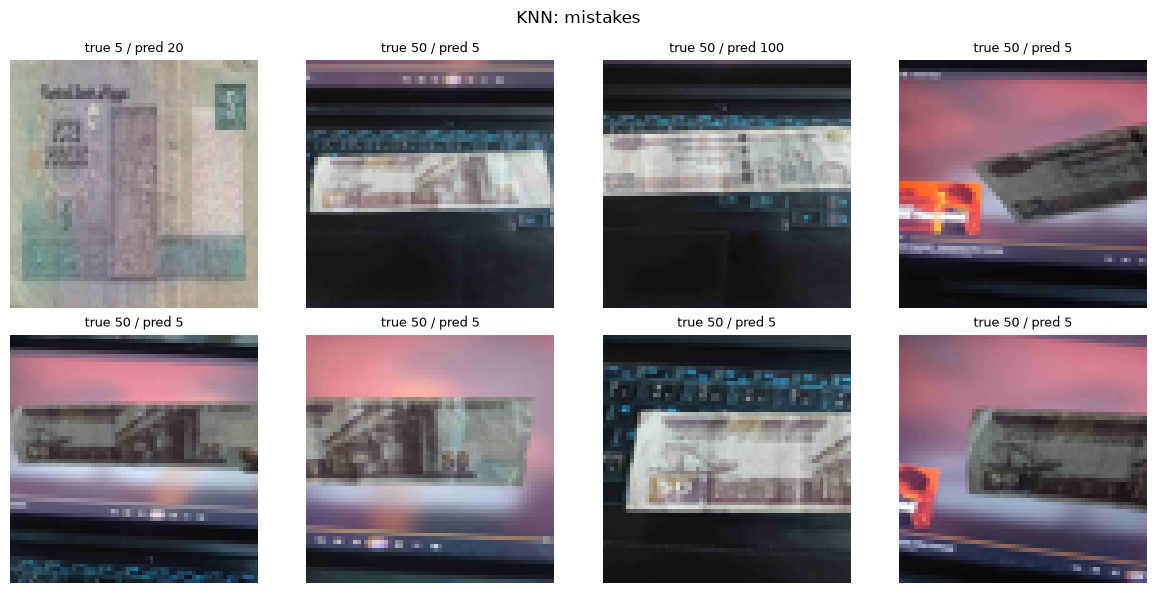

['../../models/part_b_knn.joblib']

In [5]:
cfg = CONFIG["knn"]
Xtr, Xte = get_features(cfg["features"])
knn = KNeighborsClassifier(n_neighbors=cfg["k"], weights=cfg["weights"]).fit(Xtr, y_train)
pred_knn = knn.predict(Xte)

acc = accuracy_score(y_test, pred_knn)
print("KNN test accuracy:", round(acc, 4))
tbl = per_class_table(y_test, pred_knn); print(tbl)
cm = plot_cm(y_test, pred_knn, f"KNN ({cfg['features']}, k={cfg['k']})", "cm_knn.png")
print("most confused (true, predicted, count):", top_confusions(cm))
tbl.to_csv(RESULTS / "per_class_knn.csv")
show_errors(pred_knn, "KNN: mistakes", "errors_knn.png")

summary.append({"model": "KNN", "features": cfg["features"], "setting": f"k={cfg['k']}, weights={cfg['weights']}",
                "accuracy": acc, "macro_f1": f1_score(y_test, pred_knn, average="macro")})
joblib.dump({"model": knn, "features": cfg["features"], "classes": CLASSES}, MODELS / "part_b_knn.joblib")

## 3. K-Means
Fit on train features only. The cluster -> label mapping comes from the **train** labels. The test images are only assigned to the nearest cluster.

K-Means test accuracy: 0.2993 | silhouette (test): 0.1687
cluster -> label mapping: {0: '100', 1: '10', 2: '10', 3: '20', 4: '5'}
classes covered by the mapping: 4 of 5
true class  10  100  20   5  50
cluster                        
0           22   24  45  30  20
1           12    0   1   0   7
2           26    0   4   3  31
3            0   10   0   0   0
4            0   21  10  26   2
           precision  recall  f1-score  support
5              0.441   0.441     0.441     59.0
10             0.452   0.633     0.528     60.0
20             0.000   0.000     0.000     60.0
50             0.000   0.000     0.000     60.0
100            0.170   0.436     0.245     55.0
macro avg      0.213   0.302     0.243    294.0


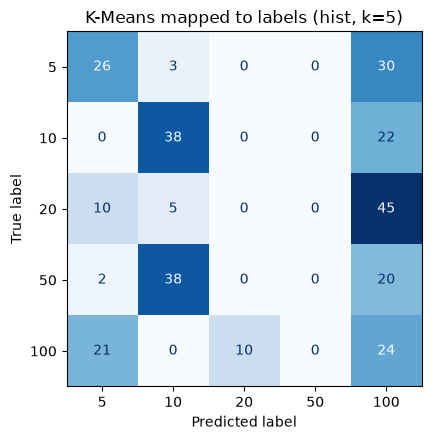

['../../models/part_b_kmeans.joblib']

In [6]:
cfg = CONFIG["kmeans"]; K = cfg["n_clusters"]
Xtr, Xte = get_features(cfg["features"])
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xtr)

mapping = {c: int(np.bincount(y_train[km.labels_ == c], minlength=len(CLASSES)).argmax())
           if (km.labels_ == c).any() else -1 for c in range(K)}
clusters_te = km.predict(Xte)
pred_km = np.array([mapping[c] for c in clusters_te])

acc = accuracy_score(y_test, pred_km)
sil = silhouette_score(Xte, clusters_te) if len(set(clusters_te)) >= 2 else float("nan")
print("K-Means test accuracy:", round(acc, 4), "| silhouette (test):", round(sil, 4))
print("cluster -> label mapping:", {c: (CLASSES[l] if l >= 0 else None) for c, l in mapping.items()})
print("classes covered by the mapping:", len(set(mapping.values())), "of", len(CLASSES))

ct = pd.crosstab(pd.Series(clusters_te, name="cluster"),
                 pd.Series([CLASSES[i] for i in y_test], name="true class"))
print(ct)
ct.to_csv(RESULTS / "kmeans_cluster_vs_class_test.csv")
tbl = per_class_table(y_test, pred_km); print(tbl)
tbl.to_csv(RESULTS / "per_class_kmeans.csv")
cm = plot_cm(y_test, pred_km, f"K-Means mapped to labels ({cfg['features']}, k={K})", "cm_kmeans.png")

summary.append({"model": "K-Means (mapped)", "features": cfg["features"], "setting": f"n_clusters={K}",
                "accuracy": acc, "macro_f1": f1_score(y_test, pred_km, average="macro"), "silhouette": sil})
joblib.dump({"kmeans": km, "mapping": mapping, "features": cfg["features"], "classes": CLASSES},
            MODELS / "part_b_kmeans.joblib")

## 4. Final comparison
The PCA object used by K-Means is `../cache/pca.joblib` (copy it next to the models for the GUI).

              model features              setting  accuracy  macro_f1  silhouette
Logistic Regression     hist                 C=10    0.3061    0.3018         NaN
                KNN     hist k=1, weights=uniform    0.2687    0.2607         NaN
   K-Means (mapped)     hist         n_clusters=5    0.2993    0.2427      0.1687


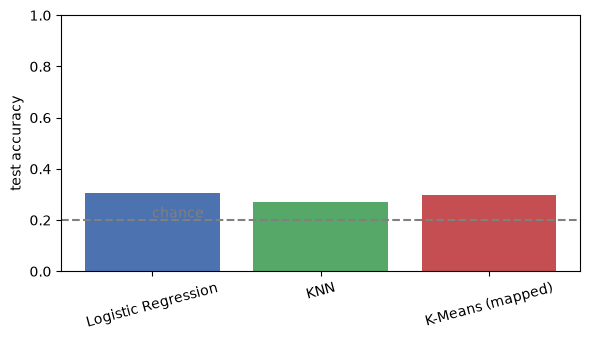

part_b_logreg 23 KB
part_b_knn 2735 KB
part_b_kmeans 16 KB


In [7]:
final = pd.DataFrame(summary).round(4)
print(final.to_string(index=False))
final.to_csv(RESULTS / "test_results_part_b.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(final["model"], final["accuracy"], color=["#4c72b0", "#55a868", "#c44e52"][:len(final)])
ax.axhline(1 / len(CLASSES), ls="--", c="gray"); ax.text(0, 1 / len(CLASSES) + 0.01, "chance", color="gray")
ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1); plt.xticks(rotation=15); plt.tight_layout()
fig.savefig(RESULTS / "test_accuracy_comparison.png", dpi=150); plt.show()

for f in ["part_b_logreg", "part_b_knn", "part_b_kmeans"]:
    print(f, (MODELS / f"{f}.joblib").stat().st_size // 1024, "KB")